In [2]:
from common import * 
from sklearn.preprocessing import PolynomialFeatures
#loading data into dataframe
df = load_data()
predictor = ["AveRooms"]

# Limit: drop outliers with an unrealistic number of average rooms
max_rooms = 40
df = df[df["AveRooms"] <= max_rooms].reset_index(drop=True)


In [3]:
#Extracting features and target variable
X = df[predictor]
y = df["MedHouseVal"]

#Defining polynomail degrees (i.e. 2)
# Extracting features and target variable
X = df[predictor]
y = df["MedHouseVal"]

# Define polynomial degree
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

model = LinearRegression()
model.fit(X_poly,y)

#prediction
y_pred = model.predict(X_poly)

#Calculating metrics
mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)




In [4]:
print(mae)
print(mse)
print(r2)

0.8684436225752014
1.2267982565668407
0.07848702957580866


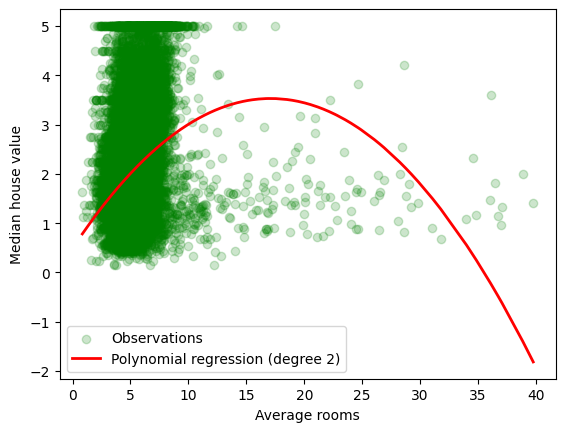

In [5]:
# Scatterplot with the degree-2 polynomial regression line
x_values = X["AveRooms"].to_numpy()
sort_order = np.argsort(x_values)
plt.scatter(x_values, y, color="green", alpha=0.2, label="Observations")
plt.plot(x_values[sort_order], y_pred[sort_order], color="red", linewidth=2, label="Polynomial regression (degree 2)")
plt.xlabel("Average rooms")
plt.ylabel("Median house value")
plt.legend()
plt.show()

In [6]:
# Simple linear regression using AveRooms to predict MedHouseVal
linear_model = LinearRegression()
linear_model.fit(X, y)

y_pred_linear = linear_model.predict(X)

# Calculate metrics
mae_linear = mean_absolute_error(y, y_pred_linear)
mse_linear = mean_squared_error(y, y_pred_linear)
r2_linear = r2_score(y, y_pred_linear)

print(f"MAE: {mae_linear}")
print(f"MSE: {mse_linear}")
print(f"R²: {r2_linear}")

MAE: 0.88560483947775
MSE: 1.2783816152478402
R²: 0.03974004421930111


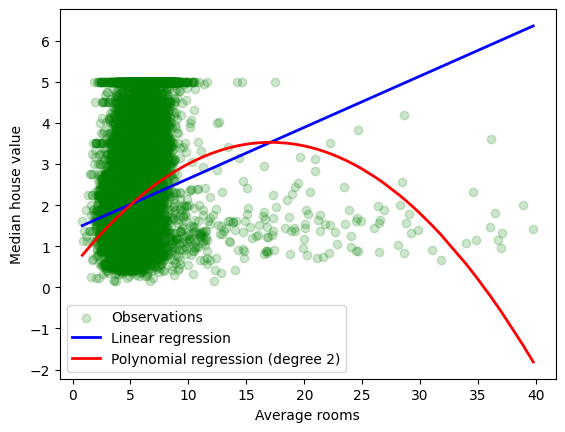

In [7]:
# Scatterplot with both the linear and the degree-2 polynomial regression lines
x_values = X["AveRooms"].to_numpy()
sort_order = np.argsort(x_values)

plt.scatter(x_values, y, color="green", alpha=0.2, label="Observations")
plt.plot(x_values[sort_order], y_pred_linear[sort_order], color="blue", linewidth=2, label="Linear regression")
plt.plot(x_values[sort_order], y_pred[sort_order], color="red", linewidth=2, label="Polynomial regression (degree 2)")
plt.xlabel("Average rooms")
plt.ylabel("Median house value")
plt.legend()
plt.show()